# 01 · Fetch and freeze all raw data

**What this notebook does.** It is the *only* notebook that touches the internet. It downloads every data source once, keeps only the columns and dates we need, and saves small CSV files in `data/raw/`. Notebooks 02–08 run offline from those files.

| # | Source | What we keep | File |
|---|---|---|---|
| 1 | FRED | Brent spot (from 1987), VIX, OVX | `brent_daily.csv`, `vix_daily.csv`, `ovx_daily.csv` |
| 2 | Caldara–Iacoviello GPR | daily geopolitical risk index | `gpr_daily.csv` |
| 3 | AI-GPR | monthly Iran geopolitical risk (robustness) | `aigpr_iran_monthly.csv` |
| 4 | GDELT 1.0 (BigQuery) | daily Iran article counts + conflict/cooperation + tone + Goldstein | `gdelt_daily.csv` |
| 5 | Dukascopy | hourly Brent bars → daily realized variance + daily OHLC | `brent_intraday_daily.csv`, `brent_intraday_removed.csv` |

Every saved file also gets a row in `data/raw/manifest.csv` (source, date range, row count, and a sha256 fingerprint).

**Freeze rule.** Everything stops at **Fri Nov 6, 2026** (`C.FREEZE_DATE`).

**Where you decide something** (the notebook stops and tells you):
1. **GDELT dating rule:** after the diagnostic query D1 (section 4a), set `D1_REVIEWED = True` below and, if needed, change `GDELT_FEED_RULE` in `config.py`.
2. **Dukascopy terms of use:** set `INTRADAY_REDISTRIBUTE` in `config.py` (section 5b).
3. **Contract-roll rule:** set `INTRADAY_ROLL_RULE` in `config.py` (section 5d).

**Rerunning.** Each source cell skips if its file already exists. To re-download one source on purpose, set its `FORCE_FETCH` flag to `True`.

## 0 · Setup

In [1]:
# ── SETUP ──────────────────────────────────────────────────────────────────────────────
# Reload src/brent/*.py automatically when we edit them (no kernel restart needed).
# "%" lines are Jupyter commands, not Python.
%load_ext autoreload
%autoreload 2

import time                                    # to time the Dukascopy download
from importlib.metadata import version         # to record which package version downloaded the data

import matplotlib.pyplot as plt                # plotting
import numpy as np                             # maths on arrays (logs, square roots, ...)
import pandas as pd                            # tables (DataFrames) with dates

import brent                                   # our own package in src/brent/
from brent import config as C      # every constant/decision lives in config.py ("C.FREEZE_DATE" etc.)
from brent import paths            # where files live + the size-budget check
from brent import sources as S     # all download / parsing functions ("S.fetch_fred" etc.)

np.random.seed(C.SEED)                         # nothing here is random, but every notebook seeds the same way
plt.rcParams["figure.dpi"] = 100               # inline figures at 100 dpi keep the notebook file small
pd.set_option("display.width", 160)            # show wider tables before pandas wraps them

# Re-download switches. False = use the frozen file if it exists. Set one to True only on purpose.
# A dict comprehension: builds {"brent": False, "vix": False, ...} in one line.
FORCE_FETCH = {k: False for k in ["brent", "vix", "ovx", "gpr", "aigpr", "gdelt", "intraday"]}

# Decision flag: set to True only AFTER reading the D1 diagnostic (section 4a) and setting
# GDELT_FEED_RULE in config.py. Until then the main GDELT query (Q1) will not run.
# (Done on Nov 23: D1 was read and the rule decided, see the "D1 findings" cell.)
D1_REVIEWED = True


def have(name: str) -> bool:
    "True if data/raw/<name>.csv already exists (then the fetch cell skips)."
    # paths.RAW is the data/raw folder; "/" joins folder and file name; .exists() checks the disk.
    return (paths.RAW / f"{name}.csv").exists()


BYTES = {}   # GB scanned by each BigQuery query this session (printed in the checks)

### Variables this notebook uses (check these)

All values come from `src/brent/config.py`. The ones marked *decide* are set with you during this notebook; everything else is frozen from the spec.

In [2]:
# ── VARIABLES TO CHECK ─────────────────────────────────────────────────────────────────
# One table of every config value notebook 01 depends on, so you can check them in one place.
# Each entry is (name, current value from config.py, plain-language meaning).
# To change a value: edit src/brent/config.py, never this cell.
rows = [
    ("FREEZE_DATE", C.FREEZE_DATE, "last day of data for every source"),
    ("FETCH_START", C.FETCH_START, "start of VIX / GPR downloads (a month before the first week)"),
    ("BRENT_FETCH_START", C.BRENT_FETCH_START, "Brent from its first FRED day (for the 'largest since 1987' check)"),
    ("OVX_FETCH_START", C.OVX_FETCH_START, "OVX download start (OVX begins May 2007)"),
    ("FRED_SERIES", C.FRED_SERIES, "FRED series ids"),
    ("GPR_URL", C.GPR_URL, "daily GPR workbook"),
    ("AIGPR_URL", C.AIGPR_URL, "AI-GPR country file (column Iran_all)"),
    ("AIGPR_MONTHS", C.AIGPR_MONTHS, "months kept (Oct 2026 = last month published by the freeze)"),
    ("GDELT_TABLE", C.GDELT_TABLE, "BigQuery table for GDELT 1.0"),
    ("GDELT_MAX_BYTES", f"{C.GDELT_MAX_BYTES / 1e9:.0f} GB", "hard cap per query (free sandbox: 1 TB / month)"),
    ("GDELT_SWITCH_DATE", C.GDELT_SWITCH_DATE, "backfile -> daily feed switch"),
    ("GDELT_FEED_RULE", C.GDELT_FEED_RULE, "decide after D1: 'dateadded' or 'sourceurl'"),
    ("DUKASCOPY_INSTRUMENT", C.DUKASCOPY_INSTRUMENT, "Brent CFD on Dukascopy"),
    ("INTRADAY_START", C.INTRADAY_START, "first Dukascopy bar (verified below)"),
    ("INTRADAY_END_UTC", C.INTRADAY_END_UTC, "bars starting at/after this are dropped (freeze)"),
    ("INTRADAY_PRICE_SIDE", C.INTRADAY_PRICE_SIDE, "bid quotes only"),
    ("INTRADAY_DAY_END_UTC", C.INTRADAY_DAY_END_UTC, "trading day ends 22:00 UTC (≈ ICE Brent close)"),
    ("INTRADAY_ROLL_SCAN", C.INTRADAY_ROLL_SCAN, "jump scan: |r| > k x median |r| of previous `window` hours"),
    ("INTRADAY_REDISTRIBUTE", C.INTRADAY_REDISTRIBUTE, "decide in 5b (terms of use)"),
    ("INTRADAY_ROLL_RULE", C.INTRADAY_ROLL_RULE, "decide in 5d (contract rolls)"),
    ("HOURLY_SAMPLE_START", C.HOURLY_SAMPLE_START, "first full week with hourly RV (verified below)"),
]
# Turn the list into a table and use the names as row labels. The last line of a cell is displayed.
pd.DataFrame(rows, columns=["config value", "current setting", "meaning"]).set_index("config value")

,current setting,meaning
config value,,
FREEZE_DATE,2026-11-06,last day of data for every source
FETCH_START,2004-12-01,start of VIX / GPR downloads (a month before t...
BRENT_FETCH_START,1987-05-20,Brent from its first FRED day (for the 'larges...
OVX_FETCH_START,2007-05-01,OVX download start (OVX begins May 2007)
FRED_SERIES,"{'brent': 'DCOILBRENTEU', 'vix': 'VIXCLS', 'ov...",FRED series ids
GPR_URL,https://www.matteoiacoviello.com/gpr_files/dat...,daily GPR workbook
AIGPR_URL,https://www.matteoiacoviello.com/ai_gpr_files/...,AI-GPR country file (column Iran_all)
AIGPR_MONTHS,"(2004-01, 2026-10)",months kept (Oct 2026 = last month published b...
GDELT_TABLE,gdelt-bq.full.events,BigQuery table for GDELT 1.0


## 1 · FRED: Brent spot, VIX, OVX

Plain CSV downloads (no API key). FRED trims to our window on its side. Missing days (holidays, shown as `.` by FRED) are dropped, never filled.

`check_coverage` stops the notebook if a series starts too late or ends before Nov 6. FRED sometimes runs a few days behind, and we don't want a silently short series.

In [3]:
# ── FRED DOWNLOADS: Brent spot, VIX, OVX ───────────────────────────────────────────────
# One "job" per series: (key in FORCE_FETCH, output file, download start, date the series must start by)
FRED_JOBS = [
    ("brent", "brent_daily", C.BRENT_FETCH_START, C.BRENT_FETCH_START),   # Brent from 1987-05-20
    ("vix",   "vix_daily",   C.FETCH_START,       "2004-12-31"),          # need the Dec 31, 2004 value
    ("ovx",   "ovx_daily",   C.OVX_FETCH_START,   C.OVX_START),           # OVX starts in May 2007
]

for key, name, start, first_by in FRED_JOBS:
    # Already downloaded and frozen? Then do nothing (this is why reruns are instant and free).
    if have(name) and not FORCE_FETCH[key]:
        print(f"skip {name}: already frozen")
        continue                                   # jump to the next series
    series_id = C.FRED_SERIES[key]                 # e.g. "DCOILBRENTEU" for Brent
    # Download into memory; FRED returns [date, value], we rename "value" to "brent"/"vix"/"ovx".
    df = S.fetch_fred(series_id, start, C.FREEZE_DATE).rename(columns={"value": key})
    # Stop with an error if the series starts too late or ends before Nov 6, 2026 (no silent short series).
    S.check_coverage(df, "date", first_by, C.FREEZE_DATE)     # raises if too short
    # Write data/raw/<name>.csv and record it (source, dates, rows, fingerprint) in manifest.csv.
    S.save_snapshot(df, name, "FRED", S.FRED_URL.format(id=series_id, start=start, end=C.FREEZE_DATE))
    print(f"saved {name}: {len(df):,} rows, {df['date'].min().date()} -> {df['date'].max().date()}")

skip brent_daily: already frozen
skip vix_daily: already frozen
skip ovx_daily: already frozen


### This data covers three different types of data we want to find: 

- brent: DCOILBRENTEU, Brent spot (Europe, daily)
- vix: VIXCLS, The CBOE Volatility Index (VIX) tracks the stock market's expectation of 30-day volatility for the S&P 500
- OVXCLS: OVXCLS, The CBOE oil volatility index (OVX) tracks the stock market's expectation of 30-day volatility in the oil industry (oil volatility index)


## 2 · GPR (daily geopolitical risk)

The Excel workbook is read straight into memory and never saved. We keep the date and `GPRD`.

GPR can lag. If its last date is before Nov 6, we **keep the gap**: the last weeks get missing GPR, which we disclose, and nothing is filled in.

- This exact cell just fetches the gpr (geopolitical risk index)

In [4]:
# ── GPR DOWNLOAD (daily geopolitical risk, an Excel file read in memory) ───────────────
if have("gpr_daily") and not FORCE_FETCH["gpr"]:
    print("skip gpr_daily: already frozen")
else:
    # Download the .xls into memory and keep only the date and the daily index GPRD.
    gpr = S.fetch_gpr_daily(C.GPR_URL, C.FETCH_START, C.FREEZE_DATE)
    # Only the START is a hard requirement here; a late END is reported, not fatal.
    # (Passing the series' own last date as "last_by" means the end check always passes.)
    S.check_coverage(gpr, "date", "2004-12-31", gpr["date"].max())
    S.save_snapshot(gpr, "gpr_daily", "Caldara-Iacoviello GPR daily", C.GPR_URL)
    print(f"saved gpr_daily: {len(gpr):,} rows, {gpr['date'].min().date()} -> {gpr['date'].max().date()}")
    # If GPR stops before Nov 6, the last weeks will simply have no GPR value. We never invent one.
    if gpr["date"].max() < pd.Timestamp(C.FREEZE_DATE):
        print(f"WARNING: GPR ends {gpr['date'].max().date()}, before the freeze. "
              "The last weeks will have missing GPR (not filled). Record this below and tell the team.")

skip gpr_daily: already frozen


In [5]:
# Last GPR date, read from the frozen file (works on every rerun, also when the fetch cell skipped).
# S.load_raw reads data/raw/gpr_daily.csv; ["date"].max() is the latest date in it.
S.load_raw("gpr_daily")["date"].max()

Timestamp('2026-11-06 00:00:00')

**GPR coverage note:** GPR runs through **2026-11-06**, the freeze date, so there is no gap and nothing to disclose (checked Nov 23).

## 3 · AI-GPR Iran (news-driven geopolitical tension around Iran)

From `ai_gpr_country_monthly.csv` on matteoiacoviello.com (columns `Date`, `Iran_all`). Months 2004-01 → 2026-10. November 2026 could not have been published by Nov 6.

In [6]:
# ── AI-GPR IRAN DOWNLOAD (monthly, robustness only) ────────────────────────────────────
if have("aigpr_iran_monthly") and not FORCE_FETCH["aigpr"]:
    print("skip aigpr_iran_monthly: already frozen")
else:
    m0, m1 = C.AIGPR_MONTHS                        # ("2004-01", "2026-10"): first and last month kept
    aigpr = S.fetch_aigpr_iran(C.AIGPR_URL, m0, m1)   # keeps the Iran_all column only
    # "-01" turns "2004-01" into the date 2004-01-01, since months are stored as their first day.
    S.check_coverage(aigpr, "month", f"{m0}-01", f"{m1}-01")
    S.save_snapshot(aigpr, "aigpr_iran_monthly", "Iacoviello-Tong AI-GPR country monthly", C.AIGPR_URL)
    print(f"saved aigpr_iran_monthly: {len(aigpr)} months, "
          f"{aigpr['month'].min():%Y-%m} -> {aigpr['month'].max():%Y-%m}")

skip aigpr_iran_monthly: already frozen


## 4 · GDELT Iran news (Google BigQuery)

GDELT codes news articles into events (who did what to whom). The table is far too big to download, so BigQuery adds it up **per day on Google's servers** and we download only the daily totals (~8,000 rows).

**Before this section:** put `BRENT_GCP_PROJECT=<your project id>` in the git-ignored `.env` file. The id is never printed: this notebook is committed with outputs. The first query opens a browser window for the Google login.

**Cost control:** every query is first *dry-run* (free; reports how many bytes it would scan), then run with a hard cap of `GDELT_MAX_BYTES`.

Two queries:
- **D1 (diagnostic):** how GDELT dated its pre-2013 archive, which decides `GDELT_FEED_RULE`. Not saved.
- **Q1 (main):** daily counts and sentiment, saved as `gdelt_daily.csv`.

In [7]:
# ── GDELT: login and "is there anything to do?" ────────────────────────────────────────
PID = S.gcp_project_id()          # from env var BRENT_GCP_PROJECT or .env; NEVER print it
print("GCP project id: set" if PID else "GCP project id: NOT set -> GDELT cells will skip (see README)")

# GDELT only needs to run if its file is missing (or we force a re-download)...
GDELT_NEEDED = FORCE_FETCH["gdelt"] or not have("gdelt_daily")
# ...and we can only run it with a Google project id. Teammates without one simply skip.
RUN_GDELT = GDELT_NEEDED and PID is not None
print("gdelt_daily:", "needs fetching" if GDELT_NEEDED else "already frozen -> skip")

if RUN_GDELT:
    creds = S.gdelt_credentials()  # opens a browser the first time; token cached in your home folder

GCP project id: set
gdelt_daily: already frozen -> skip


### 4a · D1 diagnostic: how are the rows dated?

We read three things from D1:
- **(a) Coverage:** does the GDELT 1.0 daily feed continue through Nov 2026? If not, we need the GDELT 2.0 splice.
- **(b) Backfile dating:** pre-2013 events (the "backfile") should carry a pre-2013 `DATEADDED`. If instead they were all stamped with one 2013 bulk-load date, the `"dateadded"` rule would pile the whole archive onto one day.
- **(c) `SOURCEURL`:** is it empty for backfile rows? If so, `"sourceurl"` is a clean alternative rule.

In [8]:
# ── D1: the diagnostic query (how did GDELT date its pre-2013 archive?) ────────────────
if RUN_GDELT:
    # Put the table name into the SQL template.
    sql_d1 = S.GDELT_SQL_D1.format(table=C.GDELT_TABLE)
    # Step 1, free: ask BigQuery how many bytes the query WOULD read (a "dry run" returns no data).
    BYTES["D1"] = S.gdelt_dry_run(sql_d1, PID, creds)              # free: just the size estimate
    print(f"D1 would scan {BYTES['D1'] / 1e9:.1f} GB (cap {C.GDELT_MAX_BYTES / 1e9:.0f} GB)")
    # Safety: stop here if it is bigger than our 200 GB cap (the free tier is 1 TB per month).
    assert BYTES["D1"] <= C.GDELT_MAX_BYTES, "D1 too expensive: stop"
    # Step 2: run it for real. Only a small summary table (~550 rows) comes back; it is not saved.
    d1 = S.gdelt_query(sql_d1, PID, creds, C.GDELT_MAX_BYTES)       # kept in memory only
    print(f"D1 returned {len(d1):,} rows (not saved)")

In [9]:
# ── D1 ANALYSIS: read the three answers (a), (b), (c) ──────────────────────────────────
# Each D1 row = (year the event happened, month GDELT added it) with event counts.
if RUN_GDELT:
    # BigQuery returns nullable integers, and a few groups have no DATEADDED or SQLDATE (NA).
    # Count them, then set them aside so the comparisons below work.
    na = d1["added_yyyymm"].isna() | d1["event_year"].isna()          # True where a date is missing
    print(f"rows with a missing date: {int(na.sum())} groups, {int(d1.loc[na, 'n_events'].sum()):,} events (set aside)")
    d1c = d1.loc[~na].astype({"event_year": "int64", "added_yyyymm": "int64"})   # "~" means NOT

    # (a) Coverage: which months received new rows? Any month missing since the Apr 2013 switch?
    added = d1c.groupby("added_yyyymm")["n_events"].sum()             # events added per month
    print(f"(a) rows added from {added.index.min()} to {added.index.max()}")
    # Every month from 2013-04 to 2026-11 as a number like 201304, then: which ones never got rows?
    expected = [int(p.strftime("%Y%m")) for p in pd.period_range("2013-04", "2026-11", freq="M")]
    missing = [m for m in expected if m not in set(added.index)]
    print("    months with nothing added since 2013-04:", missing or "none")

    # (b) Backfile dating: for events dated <= 2012, which DATEADDED months do they carry?
    # One huge month is a bulk-load stamp. That is harmless for the 'dateadded' rule as long as
    # it is BEFORE Apr 2013: those rows are labelled backfile and dated by their event date (SQLDATE).
    back = d1c[d1c["event_year"] <= 2012]
    share_pre = back.loc[back["added_yyyymm"] < 201304, "n_events"].sum() / back["n_events"].sum()
    print(f"(b) share of event-year<=2012 rows with DATEADDED before 2013-04: {share_pre:.1%}")
    print("    top DATEADDED months for those rows:")
    display(back.groupby("added_yyyymm")["n_events"].sum().sort_values(ascending=False).head(8).to_frame())

    # (b2) Old events added AFTER the switch are labelled 'daily' and dated by DATEADDED, so they
    # would pile onto that month. Compare with a normal month's volume.
    late_old = (back[back["added_yyyymm"] >= 201304].groupby("added_yyyymm")["n_events"].sum()
                .sort_values(ascending=False).head(5))
    print(f"(b2) event-year<=2012 rows added after the switch (typical month after 2013-04 adds "
          f"{added[added.index >= 201304].median():,.0f} events in total):")
    display(late_old.to_frame("old events added that month"))

    # (c) SOURCEURL: empty for the archive, filled for the daily feed?
    # np.where(condition, A, B) = A where the condition is true, else B.
    d1c["era"] = np.where(d1c["added_yyyymm"] < 201304, "added before 2013-04", "added 2013-04 or later")
    url = d1c.groupby("era")[["n_events", "n_no_url"]].sum()
    url["share_without_url"] = url["n_no_url"] / url["n_events"]
    print("(c) SOURCEURL by era:")
    display(url)

    # A suggestion only; YOU confirm it in the markdown cell below and in config.py.
    old_no_url = url["share_without_url"].get("added before 2013-04", 0.0)
    if share_pre > 0.95:
        print("-> suggests GDELT_FEED_RULE = 'dateadded' (archive rows carry a DATEADDED before Apr 2013)")
    elif old_no_url > 0.95:
        print("-> suggests GDELT_FEED_RULE = 'sourceurl' (archive rows have no SOURCEURL)")
    else:
        print("-> neither rule is clean: STOP and discuss")

**D1 findings and decision** (read Nov 23, 2026)
- **Missing dates:** 3 groups, 190,740 events (0.02%) have no date. Q1's date filter drops them.
- **(a) Coverage:** rows were added every month from 2013-04 to 2026-11, none missing. GDELT 1.0 reaches the freeze, so **no GDELT 2.0 splice** is needed (`GDELT_SPLICE_WEEK` stays `None`).
- **(b) Backfile `DATEADDED`:** the pre-2013 archive carries one bulk-load stamp, **Feb 2013** (about 205 million events; 99.5% of event-year ≤ 2012 rows were added before Apr 2013). That stamp falls before the Apr 1, 2013 switch, so those rows are labelled backfile and dated by their event date (`SQLDATE`). No pile-up.
- **(c) `SOURCEURL`:** archive rows are *never* empty (0%), so the `"sourceurl"` rule cannot tell the feeds apart.
- **(b2) Late re-load:** **537,078 pre-2013 events were added in Jan 2020**, against roughly 40,000 a month in 2013 and about 3.9 million events in a normal month. Dated by their add date, they would inflate "all articles" in Soleimani week.
- **Decision:** `GDELT_FEED_RULE = "dateadded"`. A third label, **`"stale"`**, marks daily-feed events dated more than 1 year before they were added (`GDELT_STALE_AFTER_YEARS = 1`). Stale rows stay in `gdelt_daily.csv`, keyed by add date, and are dropped (and counted) when the weekly panel is built in notebook 02. The Q1 dry run with this rule scans 51.1 GB.

**Q1 follow-up (Nov 23, after `gdelt_daily.csv` was saved)**
- **The "stale" rows are current news, not old news.** On Jan 1–5, 2020 the normal feed shrinks to about 2,000–3,500 events a day, while about 100,000+ events a day arrive with a broken event date: Jan 3 alone has 348,000 Iran articles, the Soleimani strike. Elsewhere stale rows are about 25 a day (negligible). **Decision:** `GDELT_STALE_POLICY = "merge"`: notebook 02 counts stale rows as daily feed and reports how many.
- **Outage:** GDELT 1.0 has **no daily-feed rows from Jun 14 to Jul 1, 2025**, during the Israel–Iran war. Jun 13 and Jul 2 are complete days. **Decision:** fill exactly those 18 days from GDELT 2.0, level-shifted to 1.0 using the other 2025 weeks, after a correlation check (section 4c).

**GDELT 2.0 patch result (Nov 23, section 4c)**
- The overlap check passes: weekly log Iran shares of 1.0 and 2.0 correlate **0.934** over 48 weeks of 2025. The level shift is −0.109, so 2.0's share × 0.90.
- But **GDELT 2.0 is down on the same days**. It has Jun 14 only, so Jun 15 – Jul 1 (17 days) are missing from both versions: the whole GDELT project was offline. Result: the week ending Jun 20 rests on 1 day (Jun 14, from 2.0), and **the week ending Jun 27 has no GDELT data at all**.
- **Decision:** `GDELT_EMPTY_WEEK_POLICY = "locf"`. That one empty week carries the previous week's GDELT values forward: exactly what a forecaster had while GDELT was down, with no look-ahead. It is flagged in the panel (`gdelt_filled = 1`, `gdelt_days = 0`). Two or more consecutive empty weeks would stop the build (`GDELT_MAX_EMPTY_WEEKS = 1`). The Israel–Iran 2025 event study mentions the outage.


### 4b · Q1 main query: daily Iran counts and sentiment

Per day it returns: all articles, Iran articles (main measure: Iran as actor 1 or 2), Iran actor *or* location (robustness), Iran conflict vs cooperation articles (CAMEO QuadClass 3–4 vs 1–2), and article-weighted sums for tone and the Goldstein scale. The weekly shares and averages are built in notebook 02.

In [10]:
# ── Q1: the main GDELT query (daily Iran counts + sentiment), saved to gdelt_daily.csv ─
if RUN_GDELT and not D1_REVIEWED:
    print("STOP: read D1 above, set GDELT_FEED_RULE in config.py, then set D1_REVIEWED = True and rerun.")
elif RUN_GDELT:
    # Build the SQL with the decided dating rule. It also labels "stale" rows: events dated more than
    # a year before GDELT added them. (Decided later: notebook 02 counts stale rows as normal news,
    # because in Jan 2020 they turned out to be current news with a broken date.)
    sql_q1 = S.render_q1(C.GDELT_TABLE, C.GDELT_FEED_RULE)       # incl. the 'stale' label (see D1 decision)
    print(f"feed rule: {C.GDELT_FEED_RULE}; stale = daily-feed events > {C.GDELT_STALE_AFTER_YEARS} year(s) old")
    # Same two-step safety as D1: free size estimate, then refuse if above the cap.
    BYTES["Q1"] = S.gdelt_dry_run(sql_q1, PID, creds)
    print(f"Q1 would scan {BYTES['Q1'] / 1e9:.1f} GB (cap {C.GDELT_MAX_BYTES / 1e9:.0f} GB)")
    assert BYTES["Q1"] <= C.GDELT_MAX_BYTES, "Q1 too expensive: stop"
    # Run it, and turn day numbers like 20050103 into real dates.
    gdelt = S.gdelt_daily_frame(S.gdelt_query(sql_q1, PID, creds, C.GDELT_MAX_BYTES))
    S.check_coverage(gdelt, "date", "2005-01-03", gdelt["date"].max())   # start is a hard requirement
    S.save_snapshot(gdelt, "gdelt_daily", "GDELT 1.0 BigQuery", C.GDELT_TABLE)
    print(f"saved gdelt_daily: {len(gdelt):,} rows, {gdelt['date'].min().date()} -> {gdelt['date'].max().date()}")
    # One line per feed label: first/last day, number of days, total events.
    display(gdelt.groupby("feed").agg(first=("date", "min"), last=("date", "max"),
                                      days=("date", "count"), events=("n_events", "sum")))

    # Where do the stale rows land? Expect a normal small background plus a spike in Jan 2020.
    stale = gdelt[gdelt["feed"] == "stale"].set_index("date")
    daily = gdelt[gdelt["feed"] == "daily"].set_index("date")
    top = stale.nlargest(10, "n_events")[["n_events", "articles_all", "articles_iran_actor"]]
    # Share of that day's events that are stale (close to 1 = almost the whole day is "stale").
    top["stale_share_of_day"] = top["n_events"] / (top["n_events"] + daily["n_events"].reindex(top.index))
    # NOTE: the message below was written before the decision; stale rows are now MERGED in notebook 02.
    print("Days with the most stale events (these are dropped in notebook 02):")
    display(top)

In [11]:
# ── Does GDELT 1.0 reach the freeze date? ──────────────────────────────────────────────
# Does GDELT 1.0 reach the freeze? If it stops early we need the GDELT 2.0 splice (spec §6.4),
# which needs the weekly code from notebook 02 for the overlap check -> we stop and plan it together.
if have("gdelt_daily"):
    last = S.load_raw("gdelt_daily")["date"].max()
    # Allow 3 days of slack; anything earlier means the feed stopped before Nov 6, 2026.
    if last < pd.Timestamp(C.FREEZE_DATE) - pd.Timedelta(days=3):
        print(f"GDELT 1.0 stops at {last.date()}: SPLICE NEEDED. Stop here and set it up with Claude.")
    else:
        print(f"GDELT 1.0 reaches {last.date()}: no GDELT 2.0 splice needed (GDELT_SPLICE_WEEK stays None).")

GDELT 1.0 reaches 2026-11-06: no GDELT 2.0 splice needed (GDELT_SPLICE_WEEK stays None).


### 4c · GDELT 2.0 patch for the Jun 14 – Jul 1, 2025 outage

GDELT 1.0 has **no rows at all** for these 18 days, which fall in the middle of the Israel–Iran war (one of our events). The models need the Iran measure every week, so we fill exactly these days from **GDELT 2.0**:

1. Run the same Q1 query on GDELT 2.0 for the whole of 2025 (`C.GDELT_V2_PATCH_QUERY`). In 2.0 the day is the date the article was added. Saved as `gdelt_v2_2025_daily.csv` (~365 rows).
2. **Check:** on the 2025 weeks that *both* versions cover fully, their weekly log Iran shares must correlate **≥ 0.8** (`C.GDELT_SPLICE_MIN_CORR`). Otherwise we stop.
3. **Level shift:** 2.0 and 1.0 count articles differently. 2.0 is moved to 1.0's level by the average difference in weekly log shares over those weeks.

The second cell below previews steps 2–3. The final version, the same calculation for every share/tone column, is built in notebook 02 (`weekly.py`).

In [12]:
# ── GDELT 2.0 for 2025 (to fill GDELT 1.0's Jun 14 - Jul 1, 2025 outage) ───────────────
GDELT_V2_NEEDED = FORCE_FETCH["gdelt"] or not have("gdelt_v2_2025_daily")
if not GDELT_V2_NEEDED:
    print("skip gdelt_v2_2025_daily: already frozen")
elif PID is None:
    print("GCP project id not set -> skipping the GDELT 2.0 patch")
else:
    # Reuse the login from above if it exists in this session; otherwise log in (no browser: cached).
    if "creds" not in globals():
        creds = S.gdelt_credentials()                            # cached login, no browser this time
    a, b = C.GDELT_V2_PATCH_QUERY                                # (20250101, 20251231): all of 2025
    # The SAME Q1 query, pointed at the GDELT 2.0 table. All of 2025 is fetched (not just the outage),
    # because the normal 2025 weeks are needed to compare 2.0 with 1.0 (the calibration in notebook 02).
    sql_v2 = S.render_q1(C.GDELT_V2_TABLE, C.GDELT_FEED_RULE, version="v2", start=a, end=b)
    BYTES["Q1_v2"] = S.gdelt_dry_run(sql_v2, PID, creds)          # free size estimate first
    print(f"GDELT 2.0 query would scan {BYTES['Q1_v2'] / 1e9:.1f} GB (cap {C.GDELT_MAX_BYTES / 1e9:.0f} GB)")
    assert BYTES["Q1_v2"] <= C.GDELT_MAX_BYTES, "too expensive: stop"
    v2 = S.gdelt_daily_frame(S.gdelt_query(sql_v2, PID, creds, C.GDELT_MAX_BYTES))
    S.check_coverage(v2, "date", "2025-01-01", "2025-12-31")      # must cover all of 2025
    S.save_snapshot(v2, "gdelt_v2_2025_daily", "GDELT 2.0 BigQuery (2025, outage patch)", C.GDELT_V2_TABLE)
    print(f"saved gdelt_v2_2025_daily: {len(v2)} rows, {v2['date'].min().date()} -> {v2['date'].max().date()}")
    display(v2.groupby("feed").agg(days=("date", "nunique"), events=("n_events", "sum")))

skip gdelt_v2_2025_daily: already frozen


overlap: 48 weeks; correlation of weekly log Iran share 1.0 vs 2.0 = 0.934 (need >= 0.8) -> PASS
level shift (mean 1.0 - 2.0 log share): -0.109  (2.0 share x 0.90)


,v1_share_%,v2_share_%,v2_shifted_%,outage_week
date,,,,
2025-05-30,0.95,0.93,0.83,False
2025-06-06,0.94,0.93,0.83,False
2025-06-13,3.61,2.86,2.56,False
2025-06-20,NaN,11.71,10.50,True
2025-06-27,NaN,NaN,NaN,True
2025-07-04,2.07,2.30,2.06,True
2025-07-11,1.50,1.59,1.43,False
2025-07-18,0.80,1.26,1.13,False


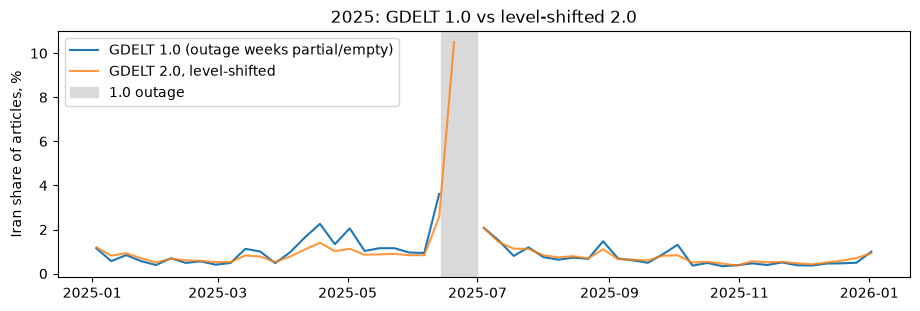

In [13]:
# ── PREVIEW: can GDELT 2.0 stand in for 1.0? ───────────────────────────────────────────
# Idea: two "thermometers" (1.0 and 2.0) that read a bit differently. On weeks where BOTH worked, we check
#   1. do they rise and fall together? (correlation, must be >= 0.8)
#   2. how far apart are they on average? (the "shift", used to convert 2.0 numbers to 1.0's scale)
# PREVIEW of the patch check (plain pandas; the tested version lives in weekly.py / notebook 02).
if have("gdelt_daily") and have("gdelt_v2_2025_daily"):
    p0, p1 = C.GDELT_V2_PATCH_DAYS                               # outage: 2025-06-14 .. 2025-07-01

    def weekly(df):
        "Weekly (Sat-Fri, labelled by the Friday) sums of Iran and all articles, 2025 only."
        d = df[df["date"].between("2025-01-01", "2025-12-31")].groupby("date")[["articles_iran_actor", "articles_all"]].sum()
        return d.resample("W-FRI").sum()                         # "W-FRI" = weeks ending on Friday

    g1 = S.load_raw("gdelt_daily")
    w1 = weekly(g1[g1["feed"].isin(["daily", "stale"])])             # stale merged (GDELT_STALE_POLICY)
    w2 = weekly(S.load_raw("gdelt_v2_2025_daily"))                   # 'v2' and 'stale' rows both count
    # Weekly log Iran share in each version: log(Iran articles / all articles).
    ls1 = np.log(w1["articles_iran_actor"] / w1["articles_all"])
    ls2 = np.log(w2["articles_iran_actor"] / w2["articles_all"])

    # Overlap = 2025 weeks fully covered by both: drop the weeks touching the outage and the partial
    # first/last weeks of the year.
    weeks = ls1.index.intersection(ls2.index)
    # A week (Sat..Fri) touches the outage if it ends on/after its first day and starts on/before its last.
    touch = (weeks >= pd.Timestamp(p0)) & (weeks - pd.Timedelta(days=6) <= pd.Timestamp(p1))
    full = (weeks - pd.Timedelta(days=6) >= pd.Timestamp("2025-01-01")) & (weeks <= pd.Timestamp("2025-12-31"))
    ov = weeks[~touch & full]
    corr = np.corrcoef(ls1[ov], ls2[ov])[0, 1]                   # do they move together? (1 = perfectly)
    shift = (ls1[ov] - ls2[ov]).mean()                               # added to 2.0's log share
    print(f"overlap: {len(ov)} weeks; correlation of weekly log Iran share 1.0 vs 2.0 = {corr:.3f} "
          f"(need >= {C.GDELT_SPLICE_MIN_CORR}) -> {'PASS' if corr >= C.GDELT_SPLICE_MIN_CORR else 'FAIL: stop and discuss'}")
    # exp(shift) turns the log difference into a multiplier, e.g. 0.90 = "1.0 reads 10% lower than 2.0".
    print(f"level shift (mean 1.0 - 2.0 log share): {shift:+.3f}  (2.0 share x {np.exp(shift):.2f})")

    # The weeks around the war: what 1.0 has (partial weeks), raw 2.0, and 2.0 shifted to 1.0's level.
    around = weeks[(weeks >= pd.Timestamp("2025-05-30")) & (weeks <= pd.Timestamp("2025-07-18"))]
    tab = pd.DataFrame({"v1_share_%": 100 * np.exp(ls1[around]), "v2_share_%": 100 * np.exp(ls2[around]),
                        "v2_shifted_%": 100 * np.exp(ls2[around] + shift), "outage_week": touch[weeks.isin(around)]})
    display(tab.round(2))

    # Plot: 1.0 and the converted 2.0 should lie on top of each other outside the grey outage band.
    fig, ax = plt.subplots(figsize=(11, 3.2))
    ax.plot(ls1.index, 100 * np.exp(ls1), label="GDELT 1.0 (outage weeks partial/empty)")
    ax.plot(ls2.index, 100 * np.exp(ls2 + shift), label="GDELT 2.0, level-shifted", alpha=0.8)
    ax.axvspan(pd.Timestamp(p0), pd.Timestamp(p1), color="0.85", label="1.0 outage")
    ax.set_ylabel("Iran share of articles, %"); ax.set_title("2025: GDELT 1.0 vs level-shifted 2.0")
    ax.legend(loc="upper left"); plt.show()

## 5 · Dukascopy hourly Brent → daily realized variance

**Why:** the professor asked for a less noisy RV. Weekly RV from 5 daily returns is noisy; from ~105 hourly returns per week it is much more precise. `rv_hourly` becomes our **main evaluation target**.

**How (all in memory):** ~83,000 hourly bid bars from Dec 2, 2010 (the first bar Dukascopy has) are downloaded, cleaned, turned into hourly returns, and summed per trading day (trading day = bars starting in [previous day 22:00, 22:00) UTC). Only the daily totals are saved. The hourly bars are deleted at the end.

The whole section skips if `brent_intraday_daily.csv` already exists.

In [14]:
# ── DUKASCOPY: is there anything to do, and which download tool works? ─────────────────
INTRADAY_NEEDED = FORCE_FETCH["intraday"] or not have("brent_intraday_daily")
# 'python' = the dukascopy-python package; 'node' = the npx command-line fallback; None = neither installed.
METHOD = S.intraday_method_available() if INTRADAY_NEEDED else None   # 'python', 'node' or None
RUN_INTRADAY = INTRADAY_NEEDED and METHOD is not None
if not INTRADAY_NEEDED:
    print("skip Dukascopy: brent_intraday_daily already frozen")
elif METHOD is None:
    print("skip Dukascopy: neither dukascopy_python nor npx is available (uv sync --group intraday)")
else:
    print(f"Dukascopy download method: {METHOD}")

Dukascopy download method: python


### 5a · Access check (one week)

Before the full download, fetch one week spanning a weekend (Wed Jan 8 → Wed Jan 15, 2025) and check that:
- the timestamps are **bar start times in UTC**;
- the first bar after the weekend opens Sunday night or early Monday UTC.

(Tested on Nov 23:
- the Python package works with the code `BRENT.CMD-USD`;
- the first bar after the weekend is Monday 01:00 UTC;
- **hourly history starts Thu Dec 2, 2010.** The `npx dukascopy-node` fallback gives the same first bar, and nothing exists before it.

Decision (Nov 23): accept the Dec 2010 start. `INTRADAY_START = 2010-12-02`, `HOURLY_SAMPLE_START = 2010-12-10` (first full week), and the hourly scaling window is Dec 10, 2010 → Dec 28, 2012 (108 weeks). HAR-X and GARCH-X start in Dec 2010. The MS models keep daily RV from 2005, and the 2013–2026 evaluation period is fully covered.)

In [15]:
# ── 5a ACCESS CHECK: one week of hourly bars, to see the format and the weekend handling ─
if RUN_INTRADAY:
    # Download Wed Jan 8 -> Wed Jan 15, 2025 (spans one weekend) and clean it (UTC, sorted, no closed-market bars).
    week = S.normalize_hourly(S.fetch_dukascopy_hourly(start="2025-01-08", end="2025-01-15", method=METHOD))
    print(week.dtypes, "\n")                   # column types: timestamps must be "UTC"
    display(week.head(3))
    # Bars that come right after a gap of more than 2 hours = session opens (daily break, weekend).
    ts = pd.DatetimeIndex(week["timestamp_utc"])
    gap_h = pd.Series(ts).diff().dt.total_seconds().to_numpy()[1:] / 3600   # hours since previous bar
    opens = pd.DataFrame({"bar_start_utc": ts[1:][gap_h > 2], "gap_hours": gap_h[gap_h > 2]})
    opens["weekday"] = opens["bar_start_utc"].dt.day_name()
    # Which trading day each opening bar is counted for (22:00 UTC day cut-off).
    opens["assigned_day"] = S.intraday_day(opens["bar_start_utc"])
    print("Bars after a gap (session opens). The weekend gap must be assigned to Monday:")
    display(opens)

timestamp_utc    datetime64[us, UTC]
open                         float64
high                         float64
low                          float64
close                        float64
volume                       float64
dtype: object 



,timestamp_utc,open,high,low,close,volume
0,2025-01-08 01:00:00+00:00,77.265,77.448,77.265,77.388,0.09113
1,2025-01-08 02:00:00+00:00,77.383,77.393,77.213,77.278,0.04813
2,2025-01-08 03:00:00+00:00,77.273,77.393,77.223,77.263,0.04008


Bars after a gap (session opens). The weekend gap must be assigned to Monday:


,bar_start_utc,gap_hours,weekday,assigned_day
0,2025-01-09 01:00:00+00:00,4.0,Thursday,2025-01-09
1,2025-01-10 01:00:00+00:00,4.0,Friday,2025-01-10
2,2025-01-13 01:00:00+00:00,52.0,Monday,2025-01-13
3,2025-01-14 01:00:00+00:00,4.0,Tuesday,2025-01-14


### 5b · Terms of use → `INTRADAY_REDISTRIBUTE`

**Decision (Nov 23, by the user): `INTRADAY_REDISTRIBUTE = False`.** The Dukascopy-derived files `brent_intraday_daily.csv` and `brent_intraday_removed.csv` stay on this machine. They are git-ignored, so they are never committed or shared.
- The committed `weekly_panel.csv` (notebook 02) still holds the weekly hourly-RV columns. It is a derived statistic, so notebooks 03–08 run for everyone.
- Rebuilding the daily files needs only this section (`uv sync --group intraday`, no account). The README says so.


In [16]:
# ── 5b: show the terms-of-use decision (set in config.py) ──────────────────────────────
print("INTRADAY_REDISTRIBUTE =", C.INTRADAY_REDISTRIBUTE,
      "(still to decide in config.py)" if C.INTRADAY_REDISTRIBUTE is None else "")

INTRADAY_REDISTRIBUTE = False 


### 5c · Full download (in memory)

Yearly chunks with retries. Expect a few minutes. We also verify the first bar date, which decides `INTRADAY_START` and `HOURLY_SAMPLE_START` (the first *full* Saturday–Friday week with hourly data).

In [17]:
# ── 5c FULL DOWNLOAD: all hourly bars since Dec 2010, kept in memory only ──────────────
if RUN_INTRADAY:
    t0 = time.time()                                       # start a stopwatch
    raw = S.fetch_dukascopy_hourly(method=METHOD)          # ~110,000 bars, memory only
    hourly = S.normalize_hourly(raw)                       # UTC, sorted, deduped, freeze cut
    print(f"{len(hourly):,} hourly bars in {time.time() - t0:.0f}s; "
          f"first {hourly['timestamp_utc'].iloc[0]}, last {hourly['timestamp_utc'].iloc[-1]}")

    # The trading day of the very first bar (iloc[[0]] = first row, kept as a list so intraday_day accepts it).
    first_day = S.intraday_day(hourly["timestamp_utc"].iloc[[0]])[0]
    # First full Sat-Fri week: the Friday ending the first bar's week if that week is fully
    # covered (first bar on/before its Saturday start), else the following Friday.
    fri = first_day + pd.Timedelta(days=(4 - first_day.weekday()) % 7)
    implied_start = fri if first_day <= fri - pd.Timedelta(days=6) else fri + pd.Timedelta(days=7)
    print(f"first trading day {first_day.date()} (config INTRADAY_START {C.INTRADAY_START})")
    print(f"implied HOURLY_SAMPLE_START {implied_start.date()} (config {C.HOURLY_SAMPLE_START})")
    # (Later decided: HOURLY_SAMPLE_START = 2013-06-07 because 2012 - May 2013 data is broken, so this
    #  line now reports a difference on purpose.)
    if str(first_day.date()) != C.INTRADAY_START or str(implied_start.date()) != C.HOURLY_SAMPLE_START:
        print("-> UPDATE config.py: INTRADAY_START / HOURLY_SAMPLE_START differ from the data")

84,367 hourly bars in 38s; first 2010-12-02 01:00:00+00:00, last 2026-11-06 21:00:00+00:00
first trading day 2010-12-02 (config INTRADAY_START 2010-12-02)
implied HOURLY_SAMPLE_START 2010-12-10 (config 2010-12-10)


### 5d · Contract rolls → `INTRADAY_ROLL_RULE` (decided with you)

The Dukascopy Brent CFD switches to the next futures contract roughly once a month. The price difference between the two contracts shows up as **one jump**, which is a level shift and not volatility, so it should not count in RV.

The scan flags every hourly return larger than **k = 8 ×** the median absolute return of the previous 120 hours (about one trading week). We look at:
- the candidates table;
- whether candidates cluster on certain days of the month (rolls are calendar-driven, news is not);
- whether they come right after a gap (`gap_hours` > 1, e.g. the Monday open);
- a price chart with the candidates marked.

**Rule:** chosen from **2010–2018 candidates only**. 2019–2026 must not influence it, since that is our test period. Then we check that the rule removes nothing near an Iran event: a real war-news jump must never be deleted as a "roll".

In [18]:
# ── 5d JUMP SCAN: suspiciously large hourly moves (possible contract rolls) ────────────
if RUN_INTRADAY:
    # Every hourly return larger than k (=8) times the typical move of the previous 120 hours.
    cand = S.roll_candidates(hourly, **C.INTRADAY_ROLL_SCAN)    # "**" passes {"k": 8, "window": 120} as k=8, window=120
    cand["date"] = S.intraday_day(cand["timestamp_utc"])
    # Only 2010-2018 is used to decide the rule; 2019+ is our test period and must not influence choices.
    early = cand[cand["date"] <= "2018-12-31"].reset_index(drop=True)   # the only ones used to choose
    print(f"{len(cand)} candidates in total, {len(early)} in 2010-2018 (used to choose the rule)")
    display(early.head(40))

    # Contract rolls happen on fixed calendar days, so they would cluster on certain days of the month.
    print("2010-2018 candidates by day of month:")
    display(early["date"].dt.day.value_counts().sort_index().to_frame("n").T)
    print(f"share right after a gap (> 1 hour): {(early['gap_hours'] > 1).mean():.0%}")
    print(f"ratio quantiles: {early['ratio'].quantile([0.5, 0.9, 1.0]).round(1).to_dict()}")

780 candidates in total, 444 in 2010-2018 (used to choose the rule)


,timestamp_utc,ret,med_abs,ratio,gap_hours,date
0,2013-05-22 15:00:00+00:00,-14.381215,0.080332,179.021420,2199.0,2013-05-22
1,2012-09-20 13:00:00+00:00,-7.613674,0.117442,64.829106,50.0,2012-09-20
2,2013-02-01 09:00:00+00:00,4.429845,0.107268,41.297120,255.0,2013-02-01
3,2012-10-19 15:00:00+00:00,-3.448008,0.117479,29.349928,64.0,2012-10-19
4,2012-07-19 13:00:00+00:00,3.342824,0.120731,27.688308,62.0,2012-07-19
5,2012-05-18 20:00:00+00:00,-4.223663,0.155309,27.195201,6.0,2012-05-18
6,2012-05-18 14:00:00+00:00,4.037078,0.153267,26.340210,12.0,2012-05-18
7,2016-12-12 01:00:00+00:00,4.284759,0.176817,24.232676,52.0,2016-12-12
8,2017-03-09 10:00:00+00:00,-2.988991,0.124833,23.943947,1.0,2017-03-09
9,2011-08-01 14:00:00+00:00,-2.250165,0.109323,20.582798,1.0,2011-08-01


2010-2018 candidates by day of month:


date,1,2,3,4,5,6,7,8,9,10,...,22,23,24,25,26,27,28,29,30,31
n,21,24,19,19,24,11,22,16,13,9,...,9,21,11,12,12,11,16,11,12,7


share right after a gap (> 1 hour): 17%
ratio quantiles: {0.5: 9.9, 0.9: 15.2, 1.0: 179.0}


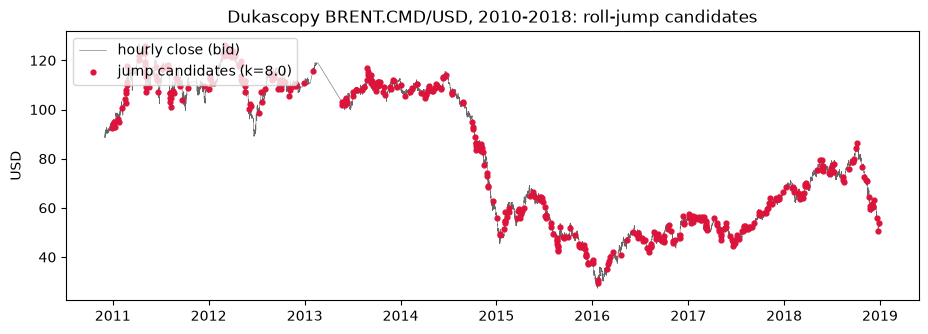

In [19]:
# ── 5d PLOT: hourly price with the jump candidates marked ──────────────────────────────
if RUN_INTRADAY:
    # Hourly close 2010-2018 with the candidates marked in red.
    h_early = hourly[hourly["timestamp_utc"] < pd.Timestamp("2019-01-01", tz="UTC")]
    # The price at each candidate's timestamp (to put the red dots on the line).
    pts = h_early.set_index("timestamp_utc").loc[early["timestamp_utc"], "close"]
    fig, ax = plt.subplots(figsize=(11, 3.5))
    ax.plot(h_early["timestamp_utc"], h_early["close"], lw=0.4, color="0.4", label="hourly close (bid)")
    ax.scatter(pts.index, pts.values, s=12, color="crimson", zorder=3, label=f"jump candidates (k={C.INTRADAY_ROLL_SCAN['k']})")
    ax.set_title("Dukascopy BRENT.CMD/USD, 2010-2018: roll-jump candidates")
    ax.set_ylabel("USD"); ax.legend(loc="upper left")
    plt.show()

**Roll-rule decision** (Nov 23, with the user): `INTRADAY_ROLL_RULE = {"kind": "gap", "max_gap_hours": 84}`

**No contract rolls are visible**, so no news jump is removed:
- The 451 candidates for 2010–2018 (k = 8) are spread evenly over every day of the month. Rolls would cluster on fixed days.
- They cluster at **13:00–16:00 UTC**, the release hours for US data and the weekly EIA oil inventory report: real news.
- Dukascopy's daily returns minus FRED Brent spot show no step around any day of the month (mean |difference| 0.8–1.6 pp on every day).

**What *is* removed:** returns that span a **hole in the data**, i.e. more than 84 hours since the previous bar. Normal weekends (~52 h) and Easter/Christmas closures (74–80 h) are kept. That is 9 returns, all before Aug 2013. The worst is −14.4%, covering Feb 20 → May 22, 2013.

**Closed-market bars** (added after the first full run): `normalize_hourly` also drops bars that start while the market is closed (any Saturday; Sunday before 22:00 UTC). In 2012–13 Dukascopy re-printed stale flat quotes on weekends, which produced 46 Sunday rows and distorted Monday's first return. Friday 22:00–23:59 bars stay and count toward the next week (48 Saturday-dated rows).

**Data-quality warning for notebook 02.** Jan 2012 – May 2013 is unreliable:
- a stale quote (111.71) is re-printed between real trades, e.g. on Sat/Sun May 19–20, 2012;
- only 12–18 bars a day, and 84 weekend bars;
- holes: Oct 18 – Nov 15, 2011 and Feb 20 – May 22, 2013.

The data is clean from 2015 and mostly clean from June 2013. Proposed for notebook 02: start the hourly sample at **2013-06-07**. The daily file keeps every day, so that decision can be made later without re-downloading.


In [20]:
# ── 5d CHECK: what does the chosen rule remove, and is anything near an Iran event? ────
# Once a rule is set: which returns would it remove in 2019-2026, and is any near an Iran event?
if RUN_INTRADAY and C.INTRADAY_ROLL_RULE is None:
    print("STOP: choose INTRADAY_ROLL_RULE in config.py (see above), then rerun from section 5d.")
elif RUN_INTRADAY:
    mask = S.roll_mask(hourly, C.INTRADAY_ROLL_RULE)           # True for each removed return
    removed_ts = mask.index[mask.to_numpy()]
    late = removed_ts[removed_ts >= pd.Timestamp("2019-01-01", tz="UTC")]
    print(f"rule {C.INTRADAY_ROLL_RULE} removes {mask.sum()} returns; {len(late)} of them in 2019-2026")
    # A real war-news jump must never be deleted: list any 2019+ removal within a week of an Iran event.
    near = []
    for ev_id, ev_date, label, _ in C.EVENTS:
        d = pd.Timestamp(ev_date, tz="UTC")
        for t in late[(late >= d - pd.Timedelta(days=7)) & (late <= d + pd.Timedelta(days=7))]:
            near.append((ev_id, ev_date, t))
    if near:
        print("REVIEW: removals within ±1 week of an Iran event (must not be real news jumps):")
        display(pd.DataFrame(near, columns=["event", "event_date", "removed_bar_utc"]))
    else:
        print("no removal within ±1 week of any Iran event")

rule {'kind': 'gap', 'max_gap_hours': 84} removes 9 returns; 0 of them in 2019-2026
no removal within ±1 week of any Iran event


### 5e · Aggregate to days and save

In [21]:
# ── 5e SAVE: hourly bars -> one row per trading day, then forget the hourly bars ───────
if RUN_INTRADAY and C.INTRADAY_ROLL_RULE is not None:
    # daily: date, rv_intraday (sum of squared hourly returns), n_hours, open/high/low/close.
    # removed: the returns the rule took out (here: 9 returns that span holes in the data).
    daily, removed = S.intraday_daily(hourly, C.INTRADAY_ROLL_RULE)
    tool = f"dukascopy-python {version('dukascopy-python')}" if METHOD == "python" else "npx dukascopy-node"
    S.save_snapshot(daily, "brent_intraday_daily", "Dukascopy BRENT.CMD/USD h1 bid", tool)
    S.save_snapshot(removed, "brent_intraday_removed", "Dukascopy BRENT.CMD/USD h1 bid", tool)
    print(f"saved brent_intraday_daily: {len(daily):,} days; brent_intraday_removed: {len(removed)} rows")
    del raw, hourly          # the hourly bars never leave memory

saved brent_intraday_daily: 4,058 days; brent_intraday_removed: 9 rows


## 6 · Checks

Each check is an `assert` that prints the offending rows if it fails. Files not fetched yet are listed at the end, and the notebook is complete only when all of them exist.

In [22]:
# ── CHECKS 1/4: FRED, GPR, AI-GPR ───────────────────────────────────────────────────────
# Each "assert" stops the notebook with a message if its condition is false.
FILES = ["brent_daily", "vix_daily", "ovx_daily", "gpr_daily", "aigpr_iran_monthly", "gdelt_daily",
         "gdelt_v2_2025_daily", "brent_intraday_daily", "brent_intraday_removed"]
FREEZE = pd.Timestamp(C.FREEZE_DATE)
raw_ = {f: S.load_raw(f) for f in FILES if have(f)}   # read back every frozen file that exists


def no_dup(df, cols, name):
    # keep=False marks ALL copies of a duplicate, so the error shows every offending row.
    dup = df[df.duplicated(cols, keep=False)]
    assert dup.empty, f"{name}: duplicate {cols}\n{dup}"


# --- FRED + GPR: one row per date, window covered ---
for name, first_by in [("brent_daily", C.BRENT_FETCH_START), ("vix_daily", "2004-12-31"),
                       ("ovx_daily", C.OVX_START), ("gpr_daily", "2004-12-31")]:
    if name in raw_:
        df = raw_[name]
        no_dup(df, ["date"], name)
        assert df["date"].min() <= pd.Timestamp(first_by), f"{name} starts {df['date'].min().date()}"
        assert df["date"].max() <= FREEZE, f"{name} has data after the freeze"
        print(f"{name:20s} {df['date'].min().date()} -> {df['date'].max().date()}  ({len(df):,} rows)")

if "brent_daily" in raw_:
    b = raw_["brent_daily"]
    # The first weekly return needs a close on Dec 31, 2004 or within 4 days before it.
    assert b["date"].between("2004-12-27", "2004-12-31").any(), "no Brent close in the last days of 2004"
    assert b["date"].max() >= FREEZE - pd.Timedelta(days=4), f"Brent ends {b['date'].max().date()}"
for name in ["vix_daily", "ovx_daily"]:
    if name in raw_:
        assert raw_[name]["date"].max() >= FREEZE - pd.Timedelta(days=4), f"{name} ends too early"

# --- AI-GPR ---
if "aigpr_iran_monthly" in raw_:
    a = raw_["aigpr_iran_monthly"]
    no_dup(a, ["month"], "aigpr")
    assert a["month"].min() <= pd.Timestamp("2004-01-01") and a["month"].max() == pd.Timestamp("2026-10-01")
    print(f"{'aigpr_iran_monthly':20s} {a['month'].min():%Y-%m} -> {a['month'].max():%Y-%m}")

brent_daily          1987-05-20 -> 2026-11-06  (9,125 rows)
vix_daily            2004-12-01 -> 2026-11-06  (5,552 rows)
ovx_daily            2007-05-10 -> 2026-11-06  (4,908 rows)
gpr_daily            2004-12-01 -> 2026-11-06  (8,011 rows)
aigpr_iran_monthly   2004-01 -> 2026-10


In [23]:
# ── CHECKS 2/4: GDELT and the GDELT 2.0 patch file ─────────────────────────────────────
# --- GDELT ---
if "gdelt_daily" in raw_:
    g = raw_["gdelt_daily"]
    no_dup(g, ["feed", "date"], "gdelt")              # one row per (feed, day)
    assert g["date"].min() <= pd.Timestamp("2005-01-03"), f"GDELT starts {g['date'].min().date()}"
    # All count columns must be >= 0 (a negative count would mean a broken query).
    counts = [c for c in S.GDELT_DAILY_COLUMNS if c.startswith(("n_", "articles_", "events_"))]
    neg = g[(g[counts] < 0).any(axis=1)]
    assert neg.empty, f"negative counts\n{neg}"
    # Conflict and cooperation are subsets of all Iran articles, so together they can't exceed it.
    bad = g[g["articles_iran_conflict"] + g["articles_iran_coop"] > g["articles_iran_actor"]]
    assert bad.empty, f"conflict + coop > Iran articles\n{bad}"
    # Gaps of more than 3 calendar days after the switch: listed, never filled.
    d = pd.Series(sorted(g.loc[g["date"] >= C.GDELT_SWITCH_DATE, "date"].unique()))
    gaps = pd.DataFrame({"after": d[:-1].to_numpy(), "next": d[1:].to_numpy()})   # each day vs the next day with data
    gaps["days"] = (gaps["next"] - gaps["after"]).dt.days
    print(f"{'gdelt_daily':20s} {g['date'].min().date()} -> {g['date'].max().date()}  ({len(g):,} rows)")
    print("GDELT gaps > 3 days since 2013-04-01:", "none" if (gaps["days"] > 3).sum() == 0 else "")
    if (gaps["days"] > 3).any():
        display(gaps[gaps["days"] > 3])

# --- GDELT 2.0 patch file: covers 2025; report which outage days it can fill ---
if "gdelt_v2_2025_daily" in raw_:
    v = raw_["gdelt_v2_2025_daily"]
    no_dup(v, ["feed", "date"], "gdelt_v2")
    assert v["date"].min() <= pd.Timestamp("2025-01-01") and v["date"].max() >= pd.Timestamp("2025-12-31")
    p0, p1 = C.GDELT_V2_PATCH_DAYS
    need = pd.date_range(p0, p1)                                     # the 18 outage days
    have_v2 = need.intersection(pd.DatetimeIndex(v.loc[v["feed"] == "v2", "date"]))   # of those, what 2.0 has
    print(f"{'gdelt_v2_2025_daily':20s} {v['date'].min().date()} -> {v['date'].max().date()}  ({len(v)} rows)")
    print(f"outage days {p0} -> {p1}: GDELT 2.0 fills {len(have_v2)} of {len(need)} "
          f"({', '.join(d.strftime('%b %d') for d in have_v2) or 'none'}); "
          f"the rest are missing in both versions -> empty week(s) handled by "
          f"GDELT_EMPTY_WEEK_POLICY = '{C.GDELT_EMPTY_WEEK_POLICY}' in notebook 02")

gdelt_daily          2005-01-01 -> 2026-11-06  (12,822 rows)
GDELT gaps > 3 days since 2013-04-01: 


,after,next,days
296,2014-01-22,2014-01-26,4
4420,2025-06-13,2025-07-02,19


gdelt_v2_2025_daily  2025-01-01 -> 2025-12-31  (696 rows)
outage days 2025-06-14 -> 2025-07-01: GDELT 2.0 fills 1 of 18 (Jun 14); the rest are missing in both versions -> empty week(s) handled by GDELT_EMPTY_WEEK_POLICY = 'locf' in notebook 02


In [24]:
# ── CHECKS 3/4: Dukascopy daily file ───────────────────────────────────────────────────
# --- Dukascopy daily ---
if "brent_intraday_daily" in raw_:
    i = raw_["brent_intraday_daily"]
    no_dup(i, ["date"], "intraday")
    assert i["date"].min() == pd.Timestamp(C.INTRADAY_START), f"intraday starts {i['date'].min().date()}"
    assert i["date"].max() == FREEZE, f"intraday ends {i['date'].max().date()}"
    # At most 24 hourly returns in a day, and a variance can never be negative.
    assert (i["n_hours"] <= 24).all() and (i["rv_intraday"] >= 0).all()
    # Sunday-evening bars belong to Monday, so a "Sunday" row would mean a bug or bad data.
    assert (i["date"].dt.day_of_week != 6).all(), "Sunday rows found (should be on Monday)"
    print("intraday rows by weekday:", i["date"].dt.day_name().value_counts().to_dict())
    short = i[i["n_hours"] < 12]                      # unusually thin days (listed, kept)
    print(f"days with fewer than 12 hourly returns: {len(short)}")
    if len(short):
        display(short.head(20))
if "brent_intraday_removed" in raw_:
    print("removed roll returns:", len(raw_["brent_intraday_removed"]))

print("BigQuery GB scanned this session:", {k: round(v / 1e9, 1) for k, v in BYTES.items()} or "none (skipped)")

intraday rows by weekday: {'Tuesday': 809, 'Thursday': 806, 'Wednesday': 804, 'Monday': 797, 'Friday': 794, 'Saturday': 48}
days with fewer than 12 hourly returns: 88


,date,rv_intraday,n_hours,open,high,low,close
227,2011-11-15,0.900765,8,111.35,112.57,111.05,112.32
273,2012-01-21,0.016151,2,110.09,110.23,110.09,110.23
279,2012-01-28,0.035501,1,111.61,111.61,111.35,111.35
285,2012-02-04,0.000684,2,114.68,114.71,114.63,114.71
291,2012-02-11,0.000650,2,117.64,117.69,117.52,117.61
317,2012-03-17,0.000000,1,125.63,125.63,125.63,125.63
323,2012-03-24,0.000000,1,124.44,124.44,124.44,124.44
329,2012-03-31,0.000000,1,122.04,122.04,122.04,122.04
334,2012-04-06,0.000000,3,122.72,122.72,122.72,122.72
335,2012-04-07,0.000000,2,122.72,122.72,122.72,122.72


removed roll returns: 9
BigQuery GB scanned this session: none (skipped)


In [25]:
# ── CHECKS 4/4: every file present, manifest, size budget ──────────────────────────────
# --- Completeness, manifest and size budget ---
missing = [f for f in FILES if not have(f)]
display(pd.read_csv(paths.RAW / "manifest.csv")) if (paths.RAW / "manifest.csv").exists() else None
paths.check_budget()                          # raises if any size limit is exceeded
print("size budget OK")
assert not missing, f"notebook 01 not complete yet, missing: {missing}"
print("notebook 01 complete: all raw files frozen")

,file,source,url_or_table,fetched_at_utc,first_date,last_date,n_rows,sha256,bytes
0,aigpr_iran_monthly.csv,Iacoviello-Tong AI-GPR country monthly,https://www.matteoiacoviello.com/ai_gpr_files/...,2026-11-24T04:27:55Z,2004-01-01,2026-10-01,274,608d90cd973e4652a3efad584ea4d32ffc365059bf151e...,5054
1,brent_daily.csv,FRED,https://fred.stlouisfed.org/graph/fredgraph.cs...,2026-11-24T04:27:54Z,1987-05-20,2026-11-06,9125,b77e6bc34d588ce0fa24b1ea00fa0517dc4d97738a0dd2...,155092
2,brent_intraday_daily.csv,Dukascopy BRENT.CMD/USD h1 bid,dukascopy-python 7.0.0,2026-11-24T05:28:53Z,2010-12-02,2026-11-06,4058,8b3e4decc3a11b61061266f73b6fc0782a8423f1e6e01e...,245595
3,brent_intraday_removed.csv,Dukascopy BRENT.CMD/USD h1 bid,dukascopy-python 7.0.0,2026-11-24T05:28:53Z,2011-11-15,2013-08-13,9,0ac7ba3f61262444f5d0eff90bc01009e34367503448e1...,626
4,gdelt_daily.csv,GDELT 1.0 BigQuery,gdelt-bq.full.events,2026-11-24T04:53:04Z,2005-01-01,2026-11-06,12822,cd9111b54281fd52658ccbda17f7da50958d4268311dee...,1081265
5,gdelt_v2_2025_daily.csv,"GDELT 2.0 BigQuery (2025, outage patch)",gdelt-bq.gdeltv2.events,2026-11-24T05:01:00Z,2025-01-01,2025-12-31,696,4e84acb0a576fd6b6f289afb6b120c29c0a5fdb2718b7f...,52745
6,gpr_daily.csv,Caldara-Iacoviello GPR daily,https://www.matteoiacoviello.com/gpr_files/dat...,2026-11-24T04:27:55Z,2004-12-01,2026-11-06,8011,3b3f0ca2ac4f14206cc13e22b19b5fdc81aa487241db55...,234038
7,ovx_daily.csv,FRED,https://fred.stlouisfed.org/graph/fredgraph.cs...,2026-11-24T04:27:54Z,2007-05-10,2026-11-06,4908,7dfbe0160b0fba6a3f8794b64a5fcb679beaece9aa9eb4...,82991
8,vix_daily.csv,FRED,https://fred.stlouisfed.org/graph/fredgraph.cs...,2026-11-24T04:27:54Z,2004-12-01,2026-11-06,5552,43229cc741d09154acd1253f9c6d9dc527859a437dde64...,93789


size budget OK
notebook 01 complete: all raw files frozen


**Before committing this notebook** (it is committed *with outputs*): restart and run all (every source cell should print `skip`). Then check that the GCP project id appears nowhere in the notebook or the manifest (`grep -c "$BRENT_GCP_PROJECT" notebooks/01_fetch_data.ipynb data/raw/manifest.csv` must print 0).